# SpaceX Falcon 9 Landing Prediction: Capstone Notebook
**How to use:** open in Google Colab, click **Runtime > Run all**, then take screenshots of the outputs for your slides.

If a download link fails, the notebook asks you to upload the file from your computer (a *Choose files* button appears).

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn folium requests beautifulsoup4 lxml

In [2]:
import pandas as pd, numpy as np, requests, sqlite3
import matplotlib.pyplot as plt, seaborn as sns
from bs4 import BeautifulSoup
sns.set_theme()
B = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/'

def load_csv(urls, label):
    """Try each URL in turn; if all fail, ask the user to upload the file."""
    for u in urls:
        try:
            d = pd.read_csv(u)
            print('Loaded', label, 'from', u)
            return d
        except Exception as e:
            print('Failed:', u, '->', type(e).__name__)
    from google.colab import files
    print(f'Please choose {label} from your computer...')
    up = files.upload()
    return pd.read_csv(list(up.keys())[0])

## 1. Data collection: SpaceX API

In [3]:
# Saved copy of the SpaceX API response (the live API is often unreliable)
url = B + 'API_call_spacex_api.json'
try:
    r = requests.get(url, timeout=30)
    launches = pd.json_normalize(r.json())
    print('Source: course copy of the SpaceX API response')
except Exception:
    r = requests.get('https://api.spacexdata.com/v4/launches/past', timeout=30)
    launches = pd.json_normalize(r.json())
    print('Source: live SpaceX API')
print(r.status_code, launches.shape)
launches[['flight_number','name','date_utc','success','rocket']].head()

Source: course copy of the SpaceX API response
200 (107, 42)


,flight_number,name,date_utc,success,rocket
0,1,FalconSat,2006-03-24T22:30:00.000Z,False,5e9d0d95eda69955f709d1eb
1,2,DemoSat,2007-03-21T01:10:00.000Z,False,5e9d0d95eda69955f709d1eb
2,3,Trailblazer,2008-08-03T03:34:00.000Z,False,5e9d0d95eda69955f709d1eb
3,4,RatSat,2008-09-28T23:15:00.000Z,True,5e9d0d95eda69955f709d1eb
4,5,RazakSat,2009-07-13T03:35:00.000Z,True,5e9d0d95eda69955f709d1eb


## 2. Data collection: web scraping (Wikipedia)

In [4]:
url = 'https://en.wikipedia.org/wiki/List_of_Falcon_9_and_Falcon_Heavy_launches'
html = requests.get(url, headers={'User-Agent':'Mozilla/5.0'}, timeout=30).text
soup = BeautifulSoup(html, 'html.parser')
tables = soup.find_all('table', class_='wikitable')
print('launch tables found:', len(tables))
print(soup.title.string)
if tables:
    first = tables[0]
    headers = [th.get_text(strip=True) for th in first.find_all('th')][:8]
    print('First table header cells:', headers)

launch tables found: 4
List of Falcon 9 and Falcon Heavy launches - Wikipedia
First table header cells: ['Flight No.', 'Date andtime (UTC)', 'Version,booster[i]', 'Launchsite', 'Payload[j]', 'Payload mass', 'Orbit', 'Customer']


## 3. Data wrangling

In [5]:
df = load_csv([B+'dataset_part_2.csv'], 'dataset_part_2.csv')
print(df.isnull().sum())
print(df['LaunchSite'].value_counts())
print(df['Orbit'].value_counts())
print(df['Outcome'].value_counts())
# Class: 1 = landing success, 0 = failure
print(df['Class'].value_counts())
print('Overall success rate:', round(df['Class'].mean(), 3))

Loaded dataset_part_2.csv from https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
Class              0
dtype: int64
LaunchSite
CCAFS SLC 40    55
KSC LC 39A      22
VAFB SLC 4E     13
Name: count, dtype: int64
Orbit
GTO      27
ISS      21
VLEO     14
PO        9
LEO       7
SSO       5
MEO       3
HEO       1
ES-L1     1
SO        1
GEO       1
Name: count, dtype: int64
Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64
Class
1    60
0    3

## 4. EDA with visualization

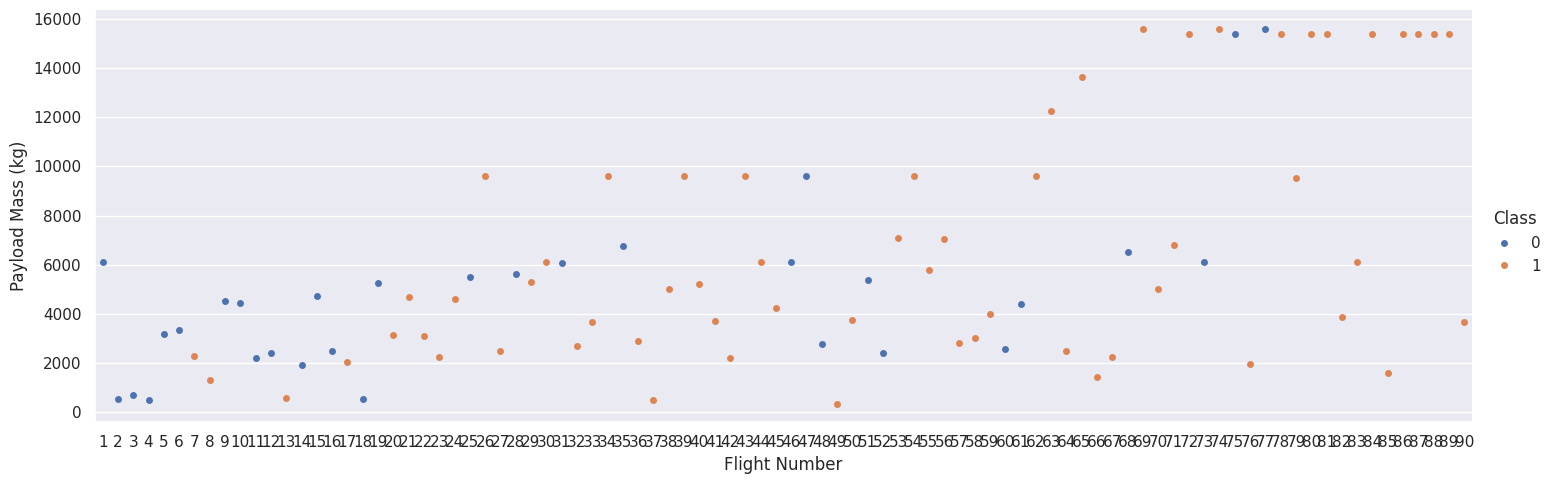

In [6]:
sns.catplot(y='PayloadMass', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number'); plt.ylabel('Payload Mass (kg)'); plt.show()

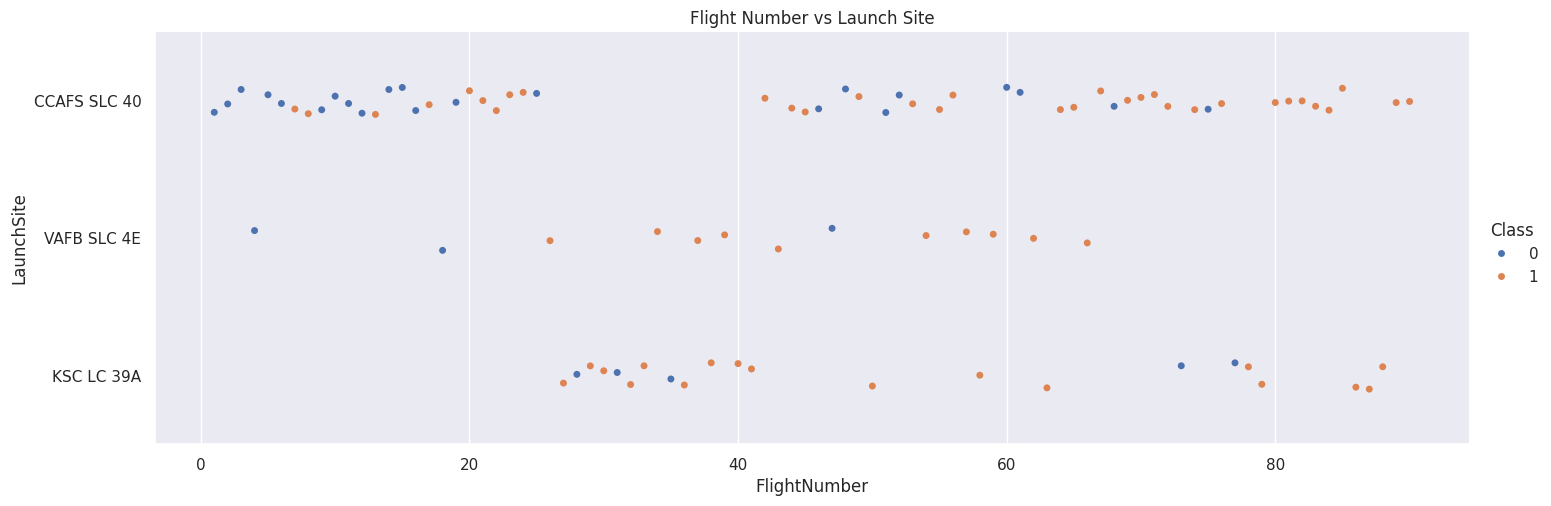

In [7]:
sns.catplot(y='LaunchSite', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.title('Flight Number vs Launch Site'); plt.show()

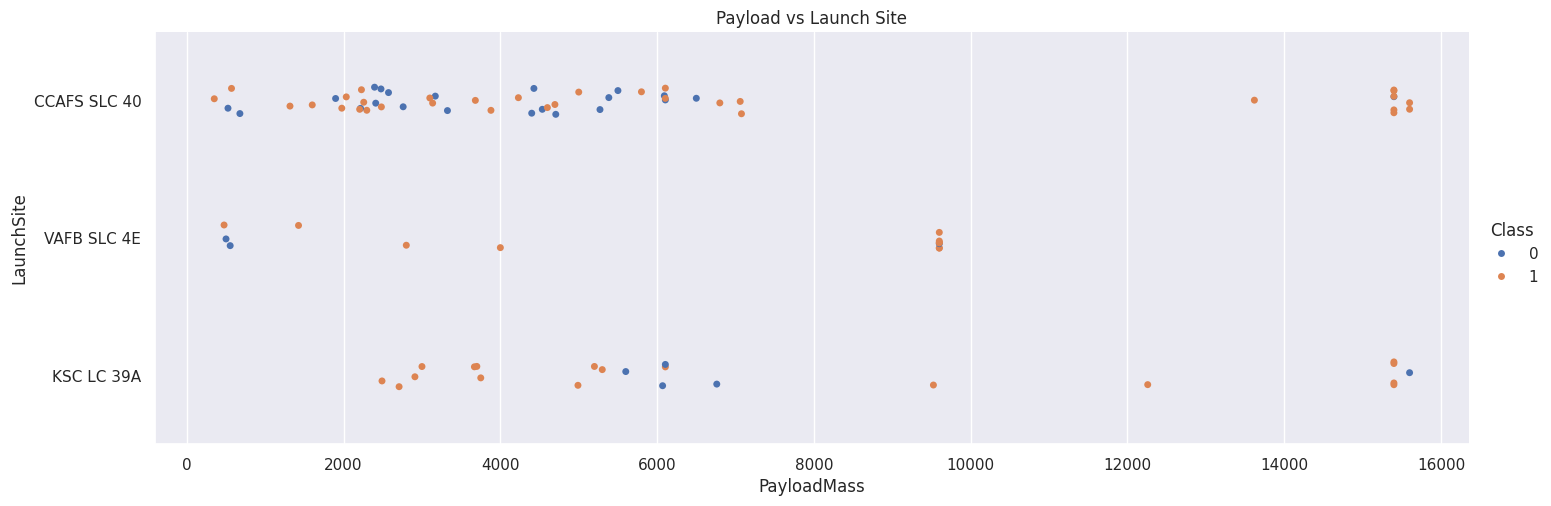

In [8]:
sns.catplot(y='LaunchSite', x='PayloadMass', hue='Class', data=df, aspect=3)
plt.title('Payload vs Launch Site'); plt.show()

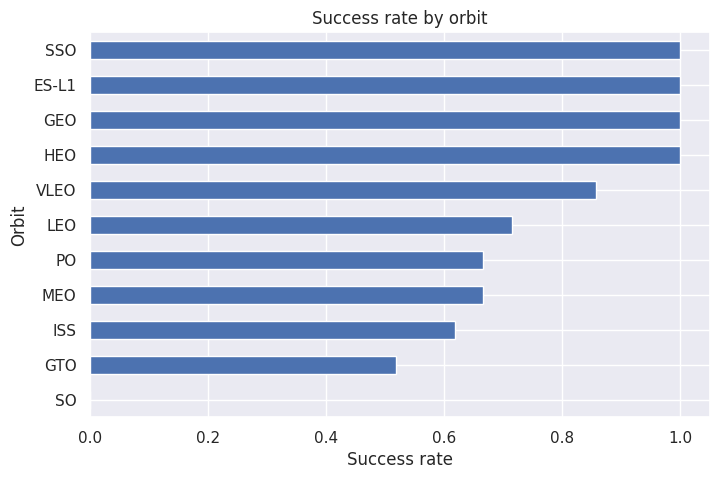

Orbit
SO       0.000
GTO      0.519
ISS      0.619
MEO      0.667
PO       0.667
LEO      0.714
VLEO     0.857
HEO      1.000
GEO      1.000
ES-L1    1.000
SSO      1.000
Name: Class, dtype: float64


In [9]:
orbit_rate = df.groupby('Orbit')['Class'].mean().sort_values()
orbit_rate.plot(kind='barh', figsize=(8,5), title='Success rate by orbit')
plt.xlabel('Success rate'); plt.show()
print(orbit_rate.round(3))

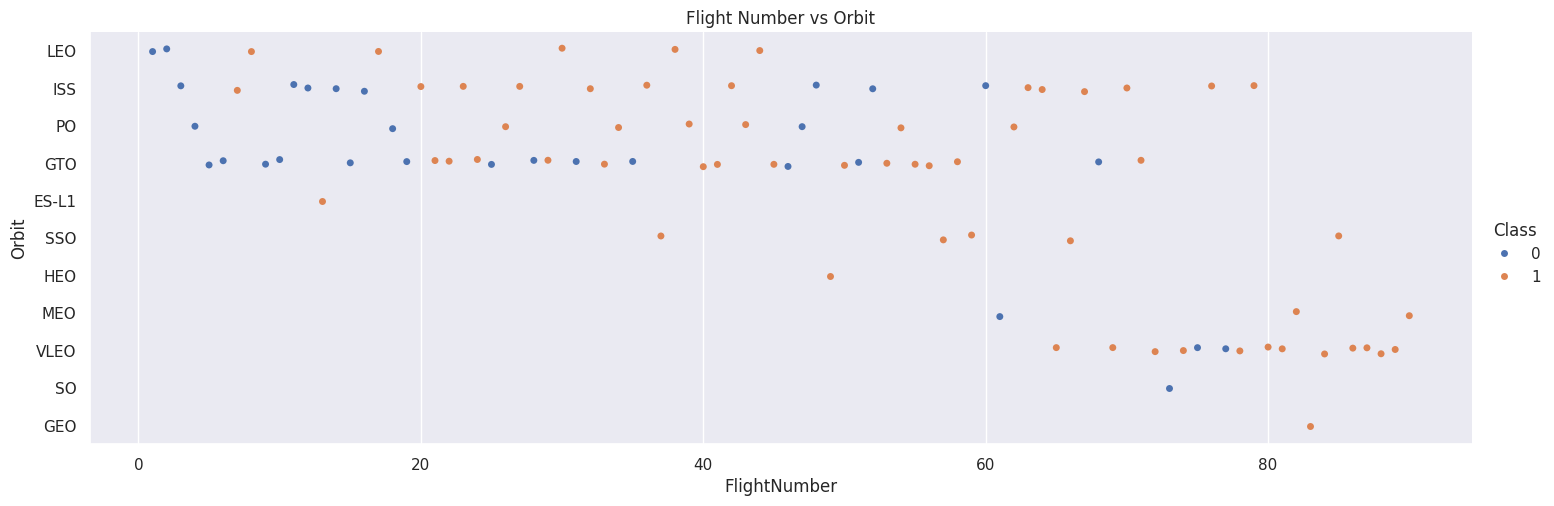

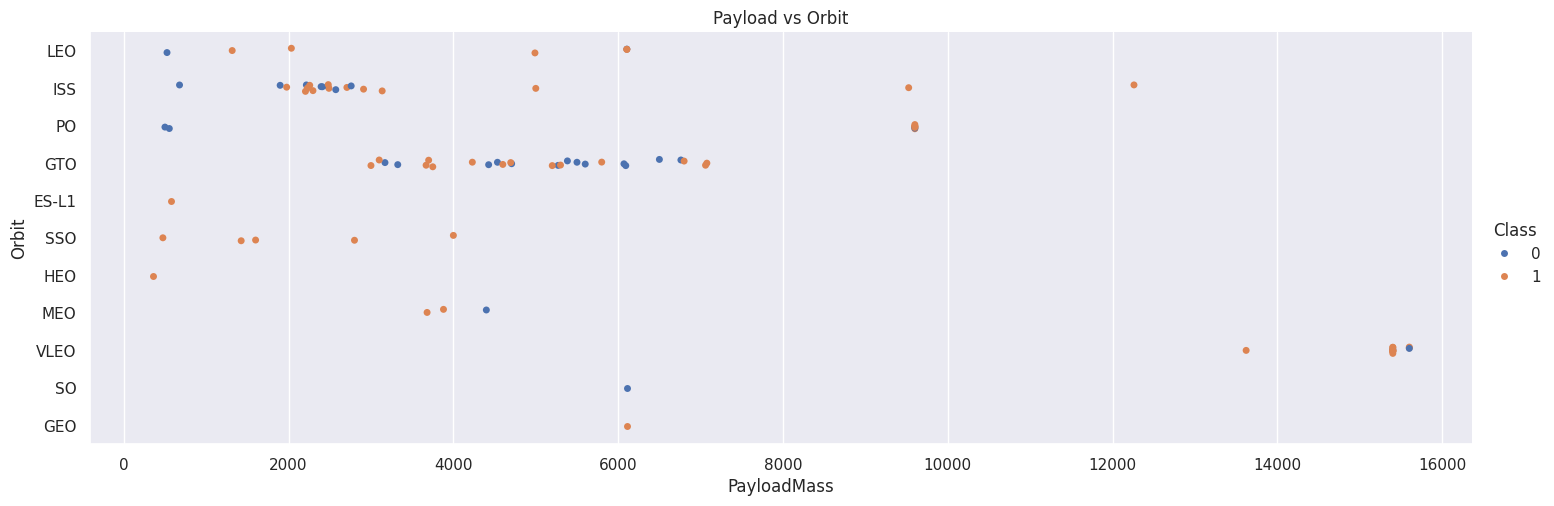

In [10]:
sns.catplot(y='Orbit', x='FlightNumber', hue='Class', data=df, aspect=3); plt.title('Flight Number vs Orbit'); plt.show()
sns.catplot(y='Orbit', x='PayloadMass', hue='Class', data=df, aspect=3); plt.title('Payload vs Orbit'); plt.show()

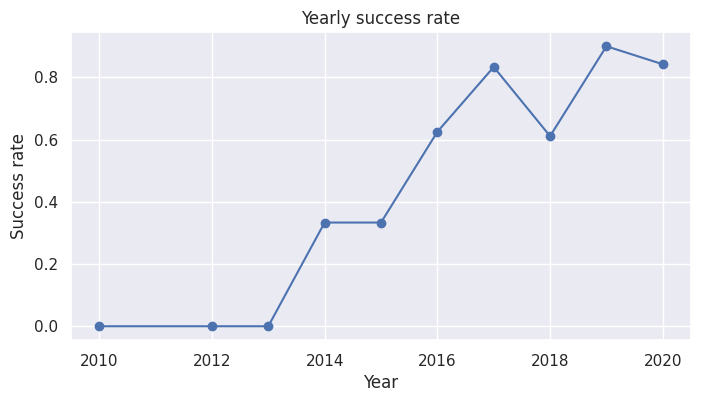

Year
2010    0.000
2012    0.000
2013    0.000
2014    0.333
2015    0.333
2016    0.625
2017    0.833
2018    0.611
2019    0.900
2020    0.842
Name: Class, dtype: float64


In [11]:
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly = df.groupby('Year')['Class'].mean()
yearly.plot(figsize=(8,4), marker='o', title='Yearly success rate')
plt.ylabel('Success rate'); plt.show()
print(yearly.round(3))

## 5. EDA with SQL

In [12]:
sq = load_csv([
    B.replace('datasets/', 'labs/module_2/data/') + 'Spacex.csv',
    B + 'Spacex.csv',
    'https://raw.githubusercontent.com/ommagdum/Applied-Data-Science-Capstone-IBM/main/Spacex.csv',
], 'Spacex.csv')
sq.columns = [c.strip() for c in sq.columns]
print(list(sq.columns))

def find(*keys):
    for c in sq.columns:
        if all(k in c.lower() for k in keys):
            return c
    raise KeyError(f'No column containing {keys}. Columns are: {list(sq.columns)}')

LS = find('launch', 'site')
PM = find('payload', 'mass')
BV = find('booster')
MO = find('mission', 'outcome')
LO = find('landing', 'outcome')
CU = find('customer')
DT = find('date')

# The date column has mixed formats, so parse each value on its own
try:
    parsed = pd.to_datetime(sq[DT], format='mixed', dayfirst=True, errors='coerce')
except (TypeError, ValueError):
    parsed = pd.to_datetime(sq[DT], dayfirst=True, errors='coerce')
sq[DT] = parsed.dt.strftime('%Y-%m-%d')
print('Dates that failed to convert:', int(sq[DT].isna().sum()))

con = sqlite3.connect(':memory:')
sq.to_sql('SPACEXTBL', con, index=False)
def q(sql): return pd.read_sql(sql, con)

Loaded Spacex.csv from https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv
['Date', 'Time (UTC)', 'Booster_Version', 'Launch_Site', 'Payload', 'PAYLOAD_MASS__KG_', 'Orbit', 'Customer', 'Mission_Outcome', 'Landing_Outcome']
Dates that failed to convert: 0


In [13]:
print('1. Unique launch sites'); display(q(f'SELECT DISTINCT "{LS}" FROM SPACEXTBL'))
print('2. Launch sites beginning with CCA'); display(q(f"SELECT * FROM SPACEXTBL WHERE \"{LS}\" LIKE 'CCA%' LIMIT 5"))
print('3. Total payload mass carried for NASA (CRS)'); display(q(f"SELECT SUM(\"{PM}\") AS total_nasa_crs FROM SPACEXTBL WHERE \"{CU}\" = 'NASA (CRS)'"))
print('4. Average payload mass, booster F9 v1.1'); display(q(f"SELECT AVG(\"{PM}\") AS avg_f9_v11 FROM SPACEXTBL WHERE \"{BV}\" LIKE 'F9 v1.1%'"))
print('5. First successful ground pad landing'); display(q(f"SELECT MIN(\"{DT}\") AS first_ground_pad_success FROM SPACEXTBL WHERE \"{LO}\" LIKE '%Success%' AND \"{LO}\" LIKE '%ground pad%'"))

1. Unique launch sites


,Launch_Site
0,CCAFS LC-40
1,VAFB SLC-4E
2,KSC LC-39A
3,CCAFS SLC-40


2. Launch sites beginning with CCA


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt


3. Total payload mass carried for NASA (CRS)


,total_nasa_crs
0,45596


4. Average payload mass, booster F9 v1.1


,avg_f9_v11
0,2534.666667


5. First successful ground pad landing


,first_ground_pad_success
0,2015-12-22


In [14]:
print('6. Drone ship success with payload 4000-6000'); display(q(f"SELECT DISTINCT \"{BV}\" FROM SPACEXTBL WHERE \"{LO}\" LIKE '%drone ship%' AND \"{LO}\" LIKE '%Success%' AND \"{PM}\" BETWEEN 4000 AND 6000"))
print('7. Mission outcome counts'); display(q(f'SELECT "{MO}", COUNT(*) AS n FROM SPACEXTBL GROUP BY "{MO}"'))
print('8. Boosters that carried the maximum payload'); display(q(f'SELECT DISTINCT "{BV}" FROM SPACEXTBL WHERE "{PM}" = (SELECT MAX("{PM}") FROM SPACEXTBL)'))
print('9. 2015 drone ship landing failures'); display(q(f"SELECT \"{DT}\", \"{BV}\", \"{LS}\", \"{LO}\" FROM SPACEXTBL WHERE \"{LO}\" LIKE '%Failure (drone ship)%' AND \"{DT}\" LIKE '2015%'"))
print('10. Landing outcomes ranked, 2010-06-04 to 2017-03-20'); display(q(f"SELECT \"{LO}\", COUNT(*) AS n FROM SPACEXTBL WHERE \"{DT}\" BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY \"{LO}\" ORDER BY n DESC"))

6. Drone ship success with payload 4000-6000


,Booster_Version
0,F9 FT B1022
1,F9 FT B1026
2,F9 FT B1021.2
3,F9 FT B1031.2


7. Mission outcome counts


,Mission_Outcome,n
0,Failure (in flight),1
1,Success,98
2,Success,1
3,Success (payload status unclear),1


8. Boosters that carried the maximum payload


,Booster_Version
0,F9 B5 B1048.4
1,F9 B5 B1049.4
2,F9 B5 B1051.3
3,F9 B5 B1056.4
4,F9 B5 B1048.5
5,F9 B5 B1051.4
6,F9 B5 B1049.5
7,F9 B5 B1060.2
8,F9 B5 B1058.3
9,F9 B5 B1051.6


9. 2015 drone ship landing failures


,Date,Booster_Version,Launch_Site,Landing_Outcome
0,2015-01-10,F9 v1.1 B1012,CCAFS LC-40,Failure (drone ship)
1,2015-04-14,F9 v1.1 B1015,CCAFS LC-40,Failure (drone ship)


10. Landing outcomes ranked, 2010-06-04 to 2017-03-20


,Landing_Outcome,n
0,No attempt,10
1,Success (drone ship),5
2,Failure (drone ship),5
3,Success (ground pad),3
4,Controlled (ocean),3
5,Uncontrolled (ocean),2
6,Failure (parachute),2
7,Precluded (drone ship),1


## 6. Folium map

In [15]:
import folium
from folium.plugins import MarkerCluster, MousePosition
from math import sin, cos, sqrt, atan2, radians

geo = load_csv([B+'spacex_launch_geo.csv'], 'spacex_launch_geo.csv')
sites = geo.groupby('Launch Site')[['Lat','Long']].first().reset_index()

# Esri satellite tiles are free and need no API key
m = folium.Map(location=[29.56, -95.09], zoom_start=4, tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}', attr='Esri World Imagery')
m.add_child(MousePosition())
for _, r in sites.iterrows():
    folium.Circle([r.Lat, r.Long], radius=1000, color='#d35400', fill=True).add_child(folium.Popup(r['Launch Site'])).add_to(m)
    folium.Marker([r.Lat, r.Long], icon=folium.DivIcon(html=f'<div style="font-size:12px;color:#d35400"><b>{r["Launch Site"]}</b></div>')).add_to(m)
mc = MarkerCluster().add_to(m)
for _, r in geo.iterrows():
    folium.Marker([r.Lat, r.Long], icon=folium.Icon(color='green' if r['class']==1 else 'red')).add_to(mc)
m

Loaded spacex_launch_geo.csv from https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/spacex_launch_geo.csv


In [16]:
def dist_km(lat1, lon1, lat2, lon2):
    R = 6373.0
    a = sin(radians(lat2-lat1)/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(radians(lon2-lon1)/2)**2
    return R*2*atan2(sqrt(a), sqrt(1-a))

# Proximity map for the Cape Canaveral site. The nearby points are approximate
# coordinates read from the map (hover with the mouse position tool to refine them).
site = sites[sites['Launch Site'].str.contains('CCAFS')].iloc[0]
points = {
    'Coastline': (28.56367, -80.57163),
    'Railway':   (28.57208, -80.58528),
    'Highway':   (28.56342, -80.57674),
    'City (Melbourne)': (28.10473, -80.64531),
}
m2 = folium.Map(location=[site.Lat, site.Long], zoom_start=11, tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}', attr='Esri World Imagery')
folium.Circle([site.Lat, site.Long], radius=500, color='#d35400', fill=True).add_child(folium.Popup(site['Launch Site'])).add_to(m2)
for name, (la, lo) in points.items():
    d = dist_km(site.Lat, site.Long, la, lo)
    folium.PolyLine([[site.Lat, site.Long], [la, lo]], weight=2).add_to(m2)
    folium.Marker([la, lo], icon=folium.DivIcon(html=f'<div style="font-size:12px"><b>{name}: {d:.2f} KM</b></div>')).add_to(m2)
    print(f'{site["Launch Site"]} to {name}: {d:.2f} km')
m2

CCAFS LC-40 to Coastline: 0.58 km
CCAFS LC-40 to Railway: 1.33 km
CCAFS LC-40 to Highway: 0.14 km
CCAFS LC-40 to City (Melbourne): 51.33 km


## 7. Predictive analysis

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

X = load_csv([B+'dataset_part_3.csv'], 'dataset_part_3.csv').astype(float)
Y = df['Class'].to_numpy()
X = StandardScaler().fit_transform(X)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)
print(X_train.shape, X_test.shape)

Loaded dataset_part_3.csv from https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_3.csv
(72, 83) (18, 83)


In [18]:
grids = {
 'Logistic Regression': (LogisticRegression(max_iter=1000), {'C':[0.01,0.1,1], 'penalty':['l2'], 'solver':['lbfgs']}),
 'SVM': (SVC(), {'kernel':['linear','rbf','poly','sigmoid'], 'C':np.logspace(-3,3,5), 'gamma':np.logspace(-3,3,5)}),
 'Decision Tree': (DecisionTreeClassifier(random_state=2), {'criterion':['gini','entropy'], 'max_depth':[2,4,6,8,10], 'min_samples_leaf':[1,2,4], 'min_samples_split':[2,5,10]}),
 'KNN': (KNeighborsClassifier(), {'n_neighbors':list(range(1,11)), 'p':[1,2], 'algorithm':['auto','ball_tree','kd_tree','brute']}),
}
results, fitted = {}, {}
for name, (est, g) in grids.items():
    gs = GridSearchCV(est, g, cv=10).fit(X_train, Y_train)
    fitted[name] = gs
    results[name] = gs.score(X_test, Y_test)
    print(f'{name}: best CV acc={gs.best_score_:.3f}, test acc={results[name]:.3f}, params={gs.best_params_}')

Logistic Regression: best CV acc=0.846, test acc=0.833, params={'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
SVM: best CV acc=0.848, test acc=0.833, params={'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
Decision Tree: best CV acc=0.871, test acc=0.778, params={'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2}
KNN: best CV acc=0.848, test acc=0.833, params={'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}


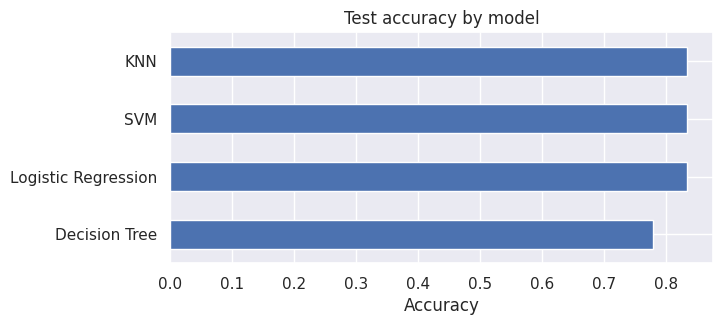

Best model: Logistic Regression 0.833


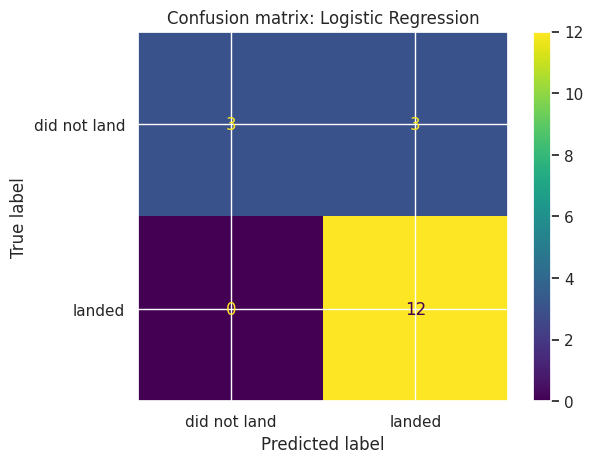

In [19]:
pd.Series(results).sort_values().plot(kind='barh', figsize=(7,3), title='Test accuracy by model')
plt.xlabel('Accuracy'); plt.show()
best = max(results, key=results.get)
print('Best model:', best, round(results[best], 3))
ConfusionMatrixDisplay(confusion_matrix(Y_test, fitted[best].predict(X_test)), display_labels=['did not land','landed']).plot()
plt.title(f'Confusion matrix: {best}'); plt.show()

## 8. Extra insight (creativity slide)
Estimated savings if first stages are reused, using the cost figures from the lab ($62M reused-booster launch vs $165M).

Predicted landings in test set: 15 of 18
Estimated saving if those boosters are reused: $1545M (illustrative)


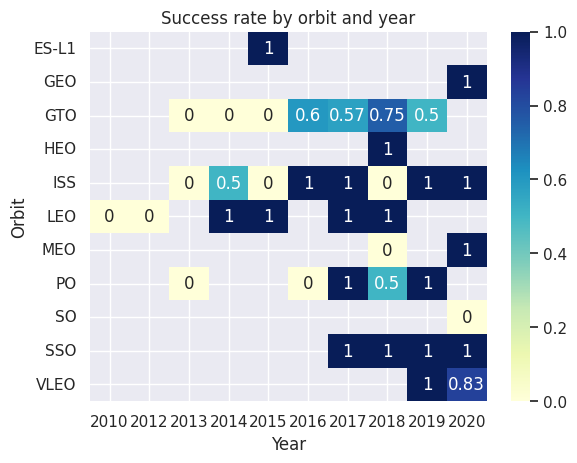

In [20]:
pred = fitted[best].predict(X_test)
landed = int(pred.sum())
print(f'Predicted landings in test set: {landed} of {len(pred)}')
print(f'Estimated saving if those boosters are reused: ${landed*(165-62)}M (illustrative)')
year_orbit = df.pivot_table(index='Orbit', columns='Year', values='Class', aggfunc='mean')
sns.heatmap(year_orbit, annot=True, cmap='YlGnBu'); plt.title('Success rate by orbit and year'); plt.show()

## 9. Summary of results (copy this text for your slides)

In [21]:
print('=== SUMMARY FOR SLIDES ===')
print('API launches collected:', launches.shape[0])
print('Launches in dataset:', len(df), '| landed:', int(df['Class'].sum()), '| success rate:', round(df['Class'].mean(), 3))
print('SQL 3, total NASA (CRS) payload kg:', q(f'''SELECT SUM("{PM}") FROM SPACEXTBL WHERE "{CU}" = 'NASA (CRS)' ''').iloc[0,0])
print('SQL 4, avg payload F9 v1.1 kg:', q(f'''SELECT AVG("{PM}") FROM SPACEXTBL WHERE "{BV}" LIKE 'F9 v1.1%' ''').iloc[0,0])
print('SQL 5, first ground pad success:', q(f'''SELECT MIN("{DT}") FROM SPACEXTBL WHERE "{LO}" LIKE '%Success%' AND "{LO}" LIKE '%ground pad%' ''').iloc[0,0])
print()
for k, v in results.items():
    print(k, '| test accuracy:', round(v, 3), '| CV accuracy:', round(fitted[k].best_score_, 3), '| params:', fitted[k].best_params_)
best = max(results, key=results.get)
pred = fitted[best].predict(X_test)
print('Best model:', best)
print('Confusion matrix [[TN, FP], [FN, TP]]:'); print(confusion_matrix(Y_test, pred))
print('Predicted landings in test set:', int(pred.sum()), 'of', len(pred))
print('Estimated saving if reused: $' + str(int(pred.sum())*(165-62)) + 'M (illustrative)')

=== SUMMARY FOR SLIDES ===
API launches collected: 107
Launches in dataset: 90 | landed: 60 | success rate: 0.667
SQL 3, total NASA (CRS) payload kg: 45596
SQL 4, avg payload F9 v1.1 kg: 2534.6666666666665
SQL 5, first ground pad success: 2015-12-22

Logistic Regression | test accuracy: 0.833 | CV accuracy: 0.846 | params: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
SVM | test accuracy: 0.833 | CV accuracy: 0.848 | params: {'C': np.float64(1.0), 'gamma': np.float64(0.03162277660168379), 'kernel': 'sigmoid'}
Decision Tree | test accuracy: 0.778 | CV accuracy: 0.871 | params: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 4, 'min_samples_split': 2}
KNN | test accuracy: 0.833 | CV accuracy: 0.848 | params: {'algorithm': 'auto', 'n_neighbors': 10, 'p': 1}
Best model: Logistic Regression
Confusion matrix [[TN, FP], [FN, TP]]:
[[ 3  3]
 [ 0 12]]
Predicted landings in test set: 15 of 18
Estimated saving if reused: $1545M (illustrative)
